<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet5%20PBL/Praktikum%202%20(JS5)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Persiapan Dataset dan Fitur

In [28]:
!pip install -q hdbscan

import hdbscan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)

# Seleksi fitur dan normalisasi skala
X_raw = df[['rating', 'review_count']].values
X = StandardScaler().fit_transform(X_raw)

print("Bentuk data siap dianalisis:", X.shape)

Bentuk data siap dianalisis: (99, 2)


#Langkah 2: Fungsi Bantu Visualisasi (plot)

In [29]:
def plot(X, labels, probabilities=None, parameters=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 2 + 6 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    title = f"Estimated number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

#Langkah 3: Eksperimen Hyperparameter min_cluster_size

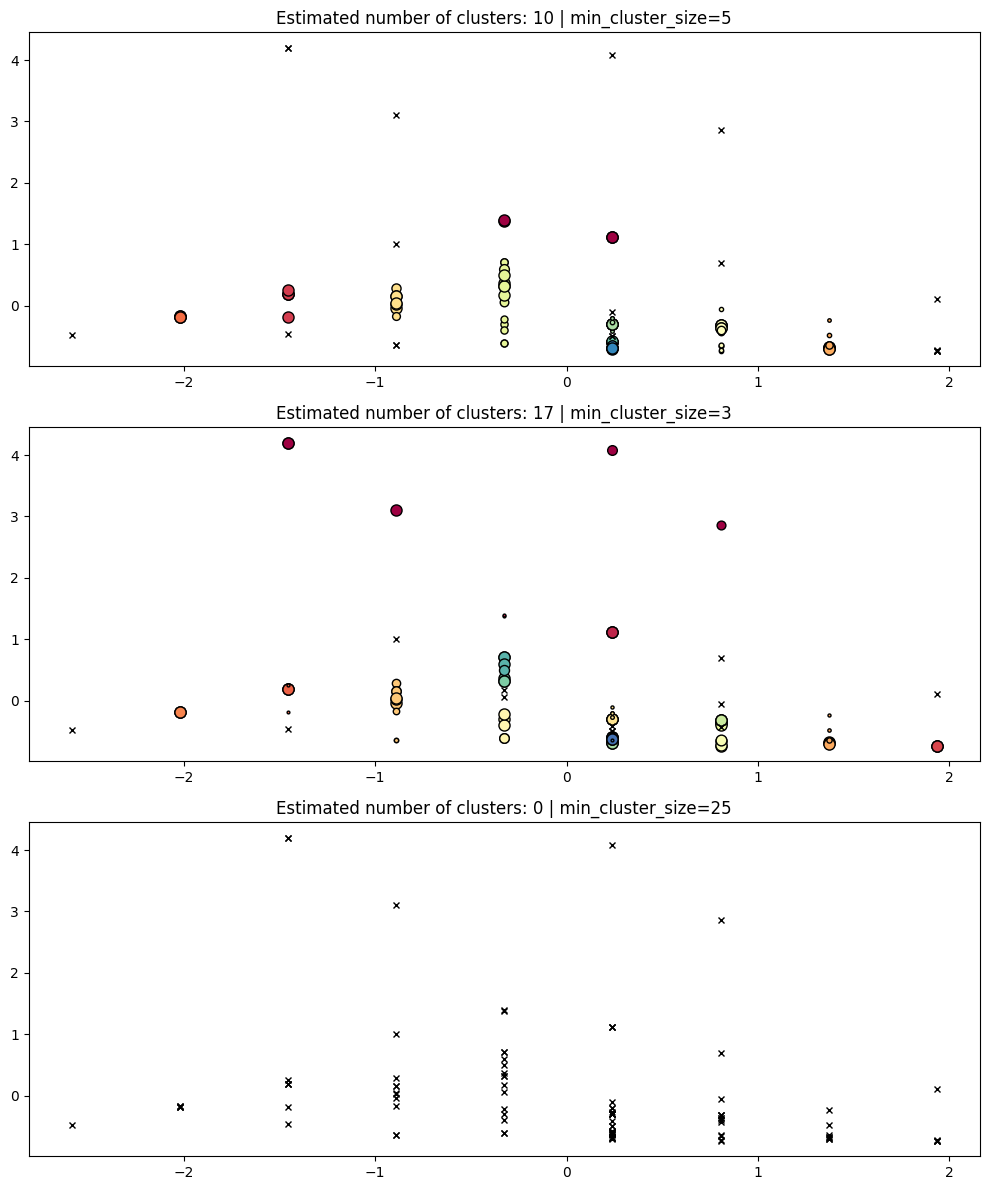

In [30]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.show()

#Langkah 4: Eksperimen Hyperparameter min_samples

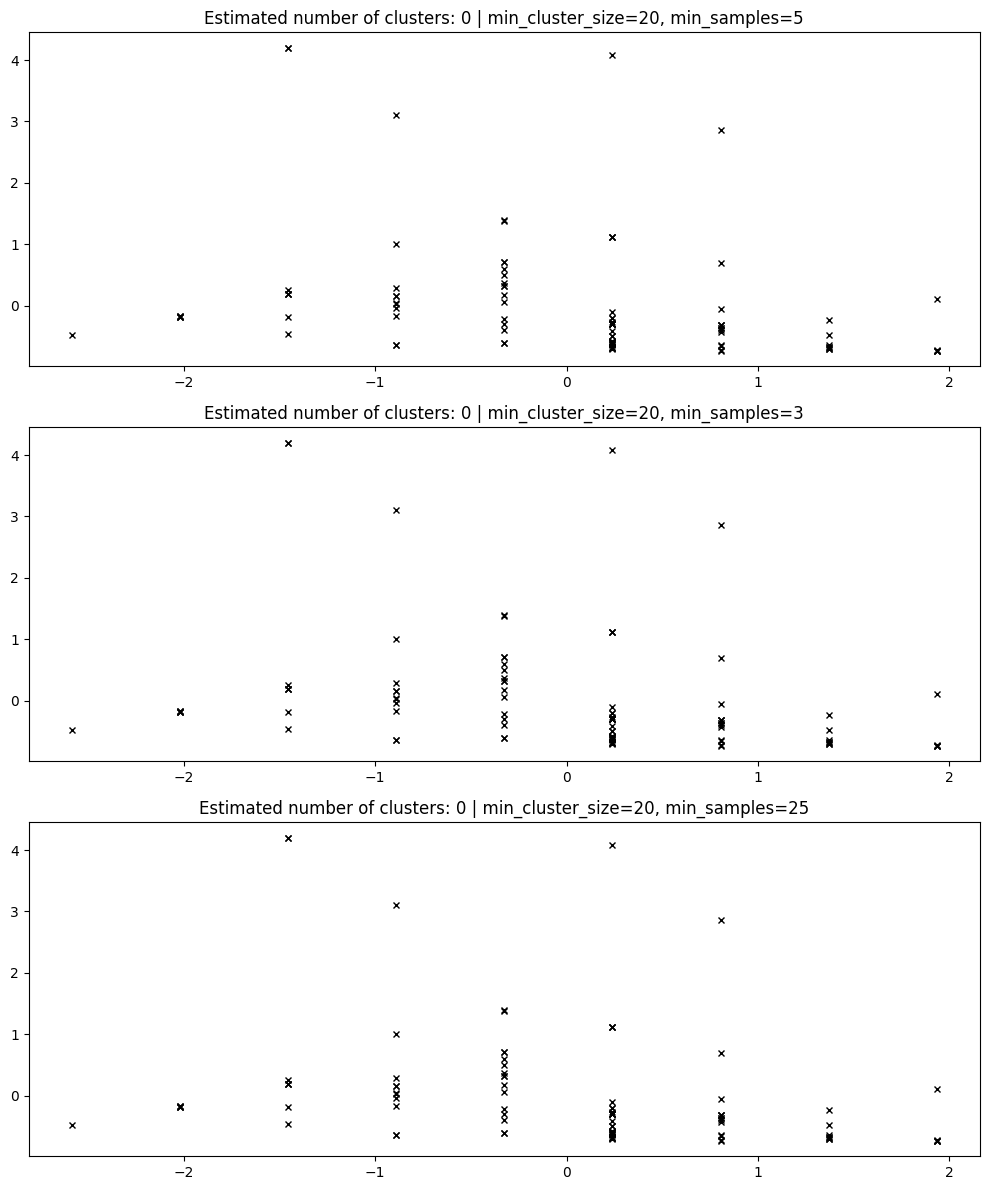

In [31]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

plt.show()

#Langkah 5: DBSCAN Clustering dari Pohon HDBSCAN (cut_distance)

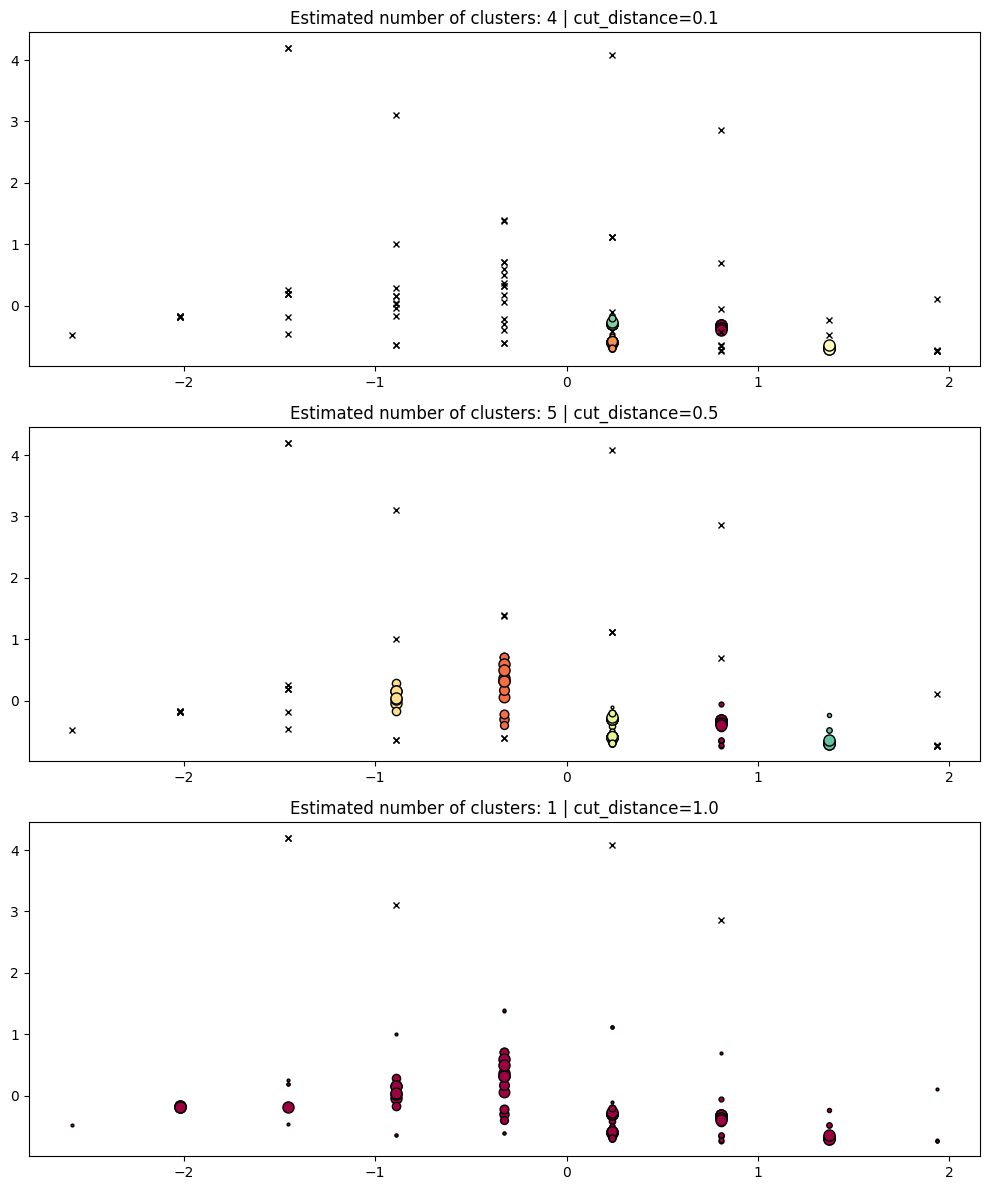

In [36]:
# 1. Pastikan X bersih dan sudah di-scaling
X_clean = np.ascontiguousarray(X)

# 2. Inisialisasi model HDBSCAN utama sesuai modul praktikum
hdb = hdbscan.HDBSCAN(min_cluster_size=5).fit(X_clean)

# 3. Parameter cut_distance sesuai Langkah 9 di jobsheet
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    # Menggunakan method dbscan_clustering asli dari library hdbscan
    labels = hdb.dbscan_clustering(**param)

    # Visualisasi
    plot(X_clean, labels, hdb.probabilities_, param, ax=axes[i])

plt.tight_layout()
plt.show()

#Langkah 6: Evaluasi dengan Silhouette Score

In [37]:
# Jalankan model HDBSCAN standar untuk evaluasi
hdb_final = HDBSCAN(min_cluster_size=5).fit(X)

# Menghitung Silhouette Score (hanya jika jumlah klaster > 1 dan mengabaikan noise -1 jika memungkinkan)
labels_eval = hdb_final.labels_
if len(set(labels_eval)) - (1 if -1 in labels_eval else 0) > 1:
    sil_score = silhouette_score(X, labels_eval)
else:
    sil_score = 0.0

print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.3641


#Langkah 7: Evaluasi dengan Davies-Bouldin Index (DBI)

In [38]:
# Menghitung Davies-Bouldin Index
if len(set(labels_eval)) - (1 if -1 in labels_eval else 0) > 1:
    dbi_score = davies_bouldin_score(X, labels_eval)
else:
    dbi_score = 0.0

print(f"Davies-Bouldin Index: {dbi_score:.4f}")

Davies-Bouldin Index: 2.3099


#Langkah 8: Visualisasi Hasil Evaluasi

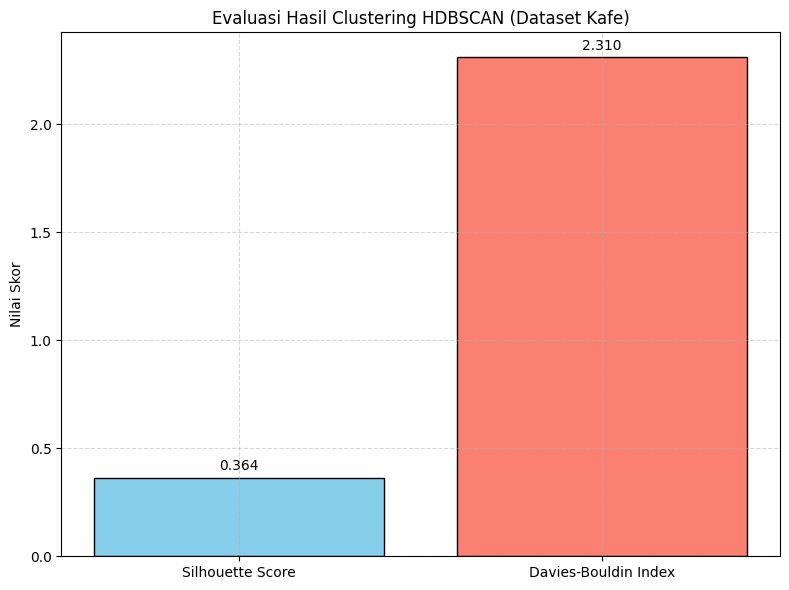

In [39]:
# Menyimpan skor ke dalam dictionary
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi dalam bentuk bar chart
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'], edgecolor='k')
ax.set_title("Evaluasi Hasil Clustering HDBSCAN (Dataset Kafe)")
ax.set_ylabel("Nilai Skor")
ax.grid(True, linestyle='--', alpha=0.5)

# Menambahkan label nilai di atas batang grafik
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom')

plt.tight_layout()
plt.show()